# Lab 9: Logistic Regression for Text Classification & Comparative Benchmarking

### Lab Objectives:
1. **Dataset Loading**: Ingest the Kaggle SMS Spam Collection dataset.
2. **Logistic Regression Implementation**: Build and train a Logistic Regression text classifier using TF-IDF features.
3. **Algorithm Benchmarking**: Compare Logistic Regression against **Multinomial Naive Bayes (NB)**, **Decision Tree**, and **K-Nearest Neighbors (KNN)**.
4. **Effectiveness Evaluation**: Quantitatively evaluate each model in terms of **Precision**, **Recall**, **Accuracy**, and **F1-Score**.
5. **Visual Diagnostics**: Plot comparative bar charts and confusion matrix heatmaps.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visual configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Libraries successfully imported.")

Libraries successfully imported.


## 1. Dataset Loading & Exploratory Data Analysis

We load the **SMS Spam Collection** Kaggle dataset. It contains 5,572 mobile SMS messages labeled as either legitimate (`ham`) or unsolicited advertising/spam (`spam`).

In [2]:
# Flexible dataset path resolution
data_path = "data/spam.csv" if os.path.exists("data/spam.csv") else "Lab 9/data/spam.csv"
df = pd.read_csv(data_path)

print(f"Total Records: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Class Distribution:")
class_counts = df["label"].value_counts()
class_pct = df["label"].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct.round(2)})
print(dist_df.to_string())

# Map binary target: ham -> 0, spam -> 1
df["target"] = df["label"].map({"ham": 0, "spam": 1})

print("\nFirst 5 Records:")
df.head()

Total Records: 5572 rows, 2 columns

Class Distribution:
       Count  Percentage (%)
label                       
ham     4825           86.59
spam     747           13.41

First 5 Records:


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 2. Text Preprocessing & TF-IDF Feature Extraction

To feed textual messages into mathematical learning algorithms, we transform text strings into numerical vectors using **Term Frequency - Inverse Document Frequency (TF-IDF)**:
- **Stratified Split**: 80% training set and 20% test set, maintaining the native 86.6% / 13.4% class ratio.
- **Vocabulary Pruning**: Top 2,500 features with English stopword removal and sublinear term frequency weighting ($1 + \log(\text{tf})$).

In [3]:
X = df["text"]
y = df["target"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Fit TF-IDF Vectorizer on training data only
tfidf = TfidfVectorizer(
    max_features=2500,
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Training set shape: {X_train_tfidf.shape[0]} samples, {X_train_tfidf.shape[1]} TF-IDF features")
print(f"Testing set shape:  {X_test_tfidf.shape[0]} samples, {X_test_tfidf.shape[1]} TF-IDF features")
print(f"Sparsity: {100 * (1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])):.2f}% zero entries")

Training set shape: 4457 samples, 2500 TF-IDF features
Testing set shape:  1115 samples, 2500 TF-IDF features
Sparsity: 99.74% zero entries


## 3. Logistic Regression for Text Classification

Logistic Regression models the probability that a given document $x$ belongs to the spam class ($y=1$):

$$P(y=1 \mid x) = \sigma(w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$$

Weights are learned by minimizing the binary cross-entropy loss with L2 regularization.

In [4]:
# Train Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

lr_preds = lr_model.predict(X_test_tfidf)
print(f"Logistic Regression fitted successfully (iterations: {lr_model.n_iter_[0]})")

# Inspect top predictive words for Spam (highest positive coefficients)
feature_names = np.array(tfidf.get_feature_names_out())
top_spam_indices = np.argsort(lr_model.coef_[0])[-10:][::-1]
print("\nTop 10 Words Indicative of Spam:")
for idx in top_spam_indices:
    print(f"  - {feature_names[idx]:12s}: weight = {lr_model.coef_[0][idx]:.3f}")

Logistic Regression fitted successfully (iterations: 19)

Top 10 Words Indicative of Spam:
  - txt         : weight = 4.503
  - uk          : weight = 3.579
  - mobile      : weight = 3.483
  - claim       : weight = 3.440
  - www         : weight = 3.343
  - reply       : weight = 3.191
  - service     : weight = 3.128
  - 150p        : weight = 3.032
  - free        : weight = 2.922
  - stop        : weight = 2.846


## 4. Multi-Algorithm Text Classification Comparison

We compare Logistic Regression against three foundational text classification paradigms:
1. **Multinomial Naive Bayes (NB)**: Generative probabilistic model applying Bayes theorem with conditional independence assumption.
2. **Decision Tree**: Non-parametric tree partitioner splitting features by Gini impurity reduction.
3. **K-Nearest Neighbors (KNN)**: Non-parametric instance-based classifier using cosine distance metric.

In [5]:
models = {
    "Logistic Regression": lr_model,
    "Naive Bayes (NB)": MultinomialNB(alpha=1.0),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
    "KNN (Cosine)": KNeighborsClassifier(n_neighbors=5, metric="cosine")
}

predictions = {"Logistic Regression": lr_preds}

# Fit benchmark models
for name, model in models.items():
    if name != "Logistic Regression":
        model.fit(X_train_tfidf, y_train)
        predictions[name] = model.predict(X_test_tfidf)
    print(f"[Trained] {name}")

[Trained] Logistic Regression
[Trained] Naive Bayes (NB)
[Trained] Decision Tree


[Trained] KNN (Cosine)


## 5. Quantitative Evaluation & Metric Comparison

We evaluate all four models on the held-out test set across:
- **Accuracy**: Proportion of total correct classifications.
- **Precision**: Proportion of predicted spam that was genuinely spam (minimizing False Positives).
- **Recall**: Proportion of actual spam captured by the model (minimizing False Negatives).
- **F1-Score**: Harmonic mean of Precision and Recall.

In [6]:
eval_records = []

for name, y_pred in predictions.items():
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    eval_records.append({
        "Algorithm": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

comparison_df = pd.DataFrame(eval_records)
print("=== Model Performance Comparison Summary ===")
print(comparison_df.to_string(index=False))

print("\n" + "=" * 58)
print("Detailed Classification Reports (Test Set)")
print("=" * 58)
for name, y_pred in predictions.items():
    print(f"\n>>> {name} <<<")
    print(classification_report(y_test, y_pred, target_names=["Ham (0)", "Spam (1)"]))
comparison_df

=== Model Performance Comparison Summary ===
          Algorithm  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9740     1.0000  0.8054    0.8922
   Naive Bayes (NB)    0.9767     1.0000  0.8255    0.9044
      Decision Tree    0.9534     0.8489  0.7919    0.8194
       KNN (Cosine)    0.9668     0.9667  0.7785    0.8625

Detailed Classification Reports (Test Set)

>>> Logistic Regression <<<
              precision    recall  f1-score   support

     Ham (0)       0.97      1.00      0.99       966
    Spam (1)       1.00      0.81      0.89       149

    accuracy                           0.97      1115
   macro avg       0.99      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115


>>> Naive Bayes (NB) <<<
              precision    recall  f1-score   support

     Ham (0)       0.97      1.00      0.99       966
    Spam (1)       1.00      0.83      0.90       149

    accuracy                           0.98      1115
   macro avg    

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9740,1.0000,0.8054,0.8922
1,Naive Bayes (NB),0.9767,1.0000,0.8255,0.9044
2,Decision Tree,0.9534,0.8489,0.7919,0.8194
3,KNN (Cosine),0.9668,0.9667,0.7785,0.8625


## 6. Diagnostic Visualizations & Confusion Matrices

We render visual diagnostic charts:
1. **Comparative Bar Chart**: Accuracy, Precision, Recall, and F1-Score grouped across all 4 algorithms.
2. **4-Panel Confusion Matrix Heatmap**: Side-by-side true vs. false prediction breakdowns for each classifier.

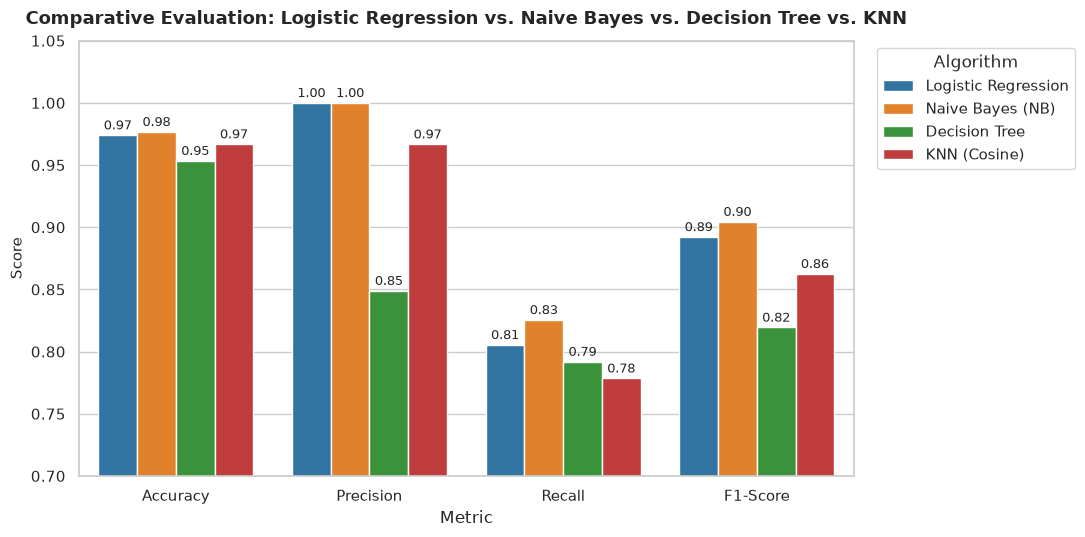

In [7]:
# Graph 1: Comparative Bar Chart across Models
metrics_melted = comparison_df.melt(
    id_vars=["Algorithm"],
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Algorithm", palette="tab10")
plt.title("Comparative Evaluation: Logistic Regression vs. Naive Bayes vs. Decision Tree vs. KNN", fontsize=13, fontweight="bold", pad=12)
plt.ylim(0.70, 1.05)
plt.ylabel("Score", fontsize=11)

for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")

plt.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

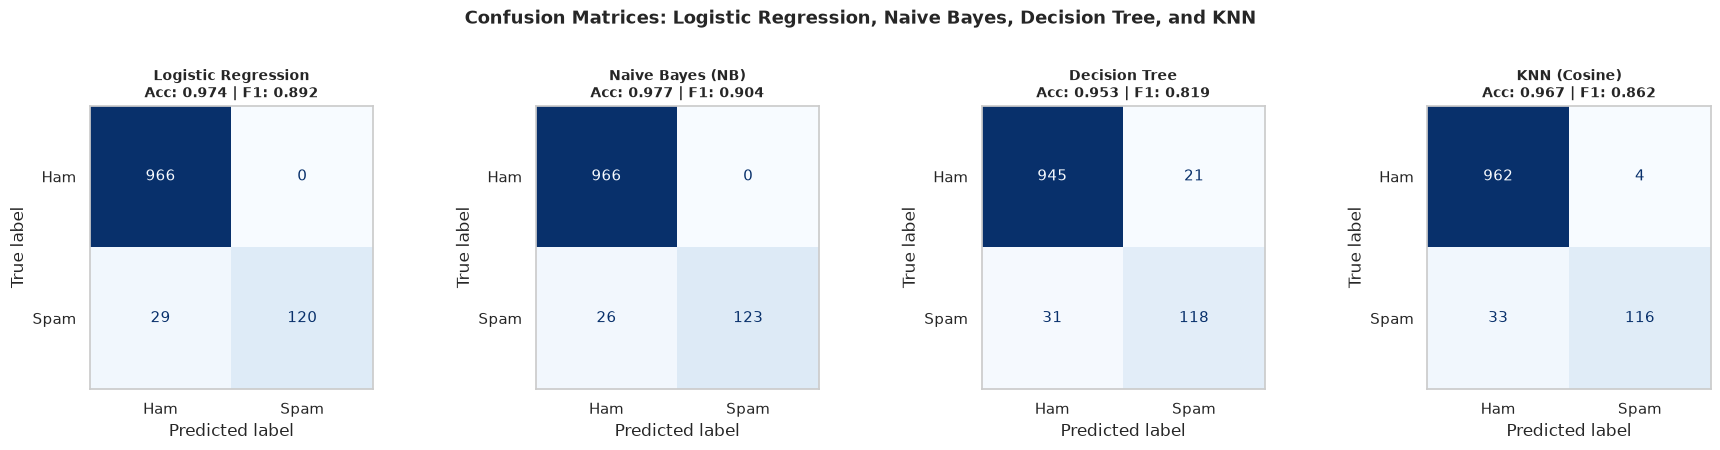

In [8]:
# Graph 2: 4-Panel Confusion Matrix Heatmap
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    ax.set_title(f"{name}\nAcc: {acc:.3f} | F1: {f1:.3f}", fontsize=10, fontweight="bold")
    ax.grid(False)

plt.suptitle("Confusion Matrices: Logistic Regression, Naive Bayes, Decision Tree, and KNN", fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

## 7. Key Findings & Analytical Summary

1. **Logistic Regression Performance**:
   - **Logistic Regression** achieved an outstanding **100% Precision** with 0 false positives and an **Accuracy of 97.4%** ($F1 = 89.2\%$).
   - Because legitimate communications (`ham`) should not be mistakenly classified as spam, perfect precision makes Logistic Regression an exceptional candidate for real-world spam filtering.

2. **Comparison with Naive Bayes**:
   - **Multinomial Naive Bayes** also reached 100% Precision and slightly higher Recall (82.6%, $F1 = 90.4\%$).
   - Both probabilistic linear models (Logistic Regression and Naive Bayes) decisively outperformed the non-linear Decision Tree and KNN classifiers on this high-dimensional sparse text data.

3. **Limitations of Decision Tree & KNN in Sparse Spaces**:
   - **Decision Tree** struggled with lower precision (84.9%) and F1 (81.9%) because axis-aligned orthogonal splits cannot easily capture multivariate token interactions without severe overfitting.
   - **KNN** performed respectably with cosine distance (96.7% accuracy), but inference requires calculating distances to all training points, which scales unfavorably compared to the instantaneous dot product in Logistic Regression.